Dataset loaded successfully!
Dataset shape: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB

Statistical Summary


,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,281.205870,0.334264,0.000222,49.362231,3259.818355
std,13.338232,44.789133,0.008168,39.015750,1986.860670
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,1193.000000
50%,282.450000,0.000000,0.000000,64.000000,3380.000000
75%,291.806000,0.000000,0.000000,90.000000,4933.000000
max,310.070000,9831.300000,0.510000,100.000000,7280.000000



Missing Values
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64

Duplicate Records
Number of duplicates: 17

Dataset Columns
['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume']

Dataset shape after cleaning: (48187, 9)


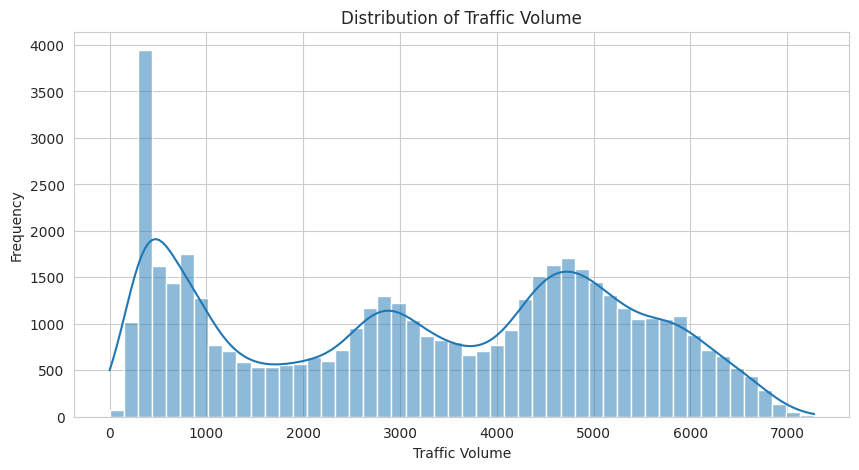

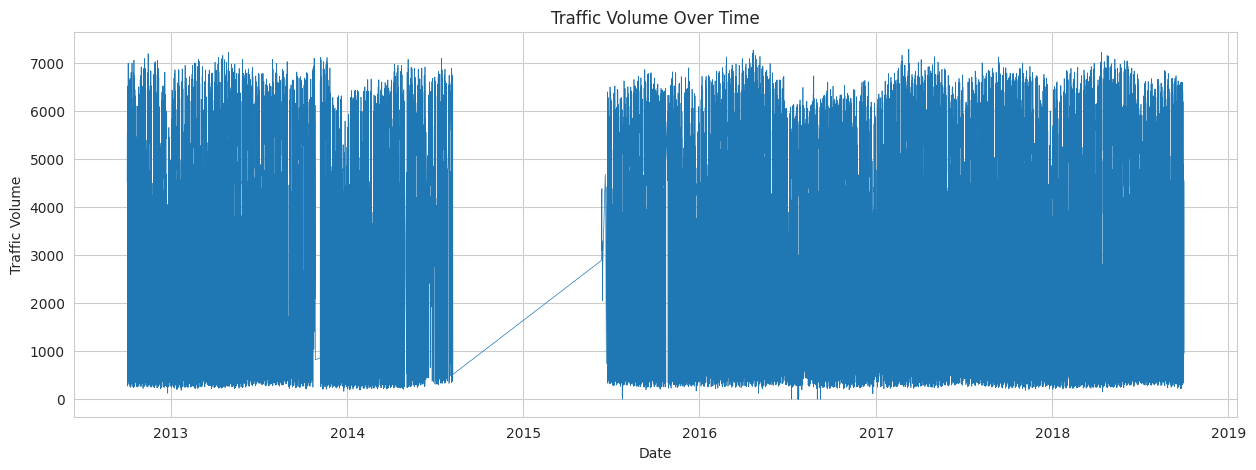

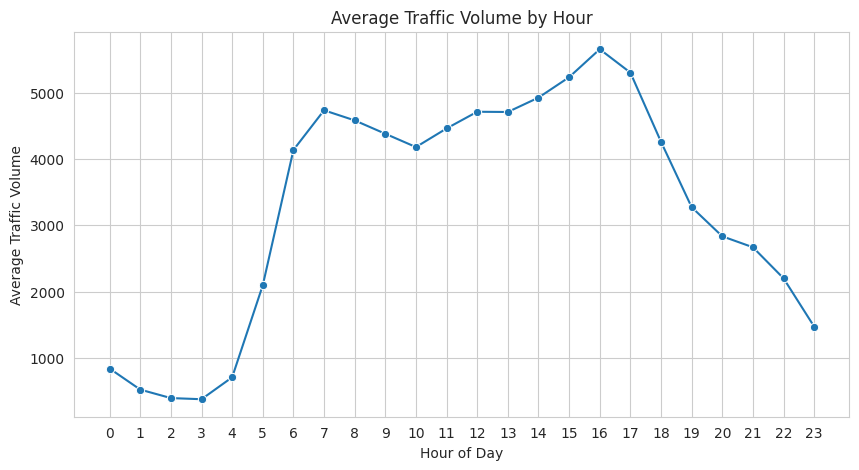

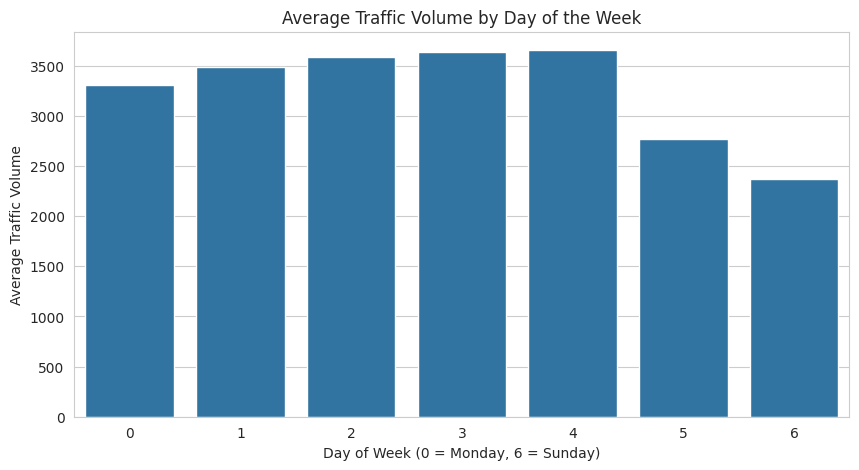

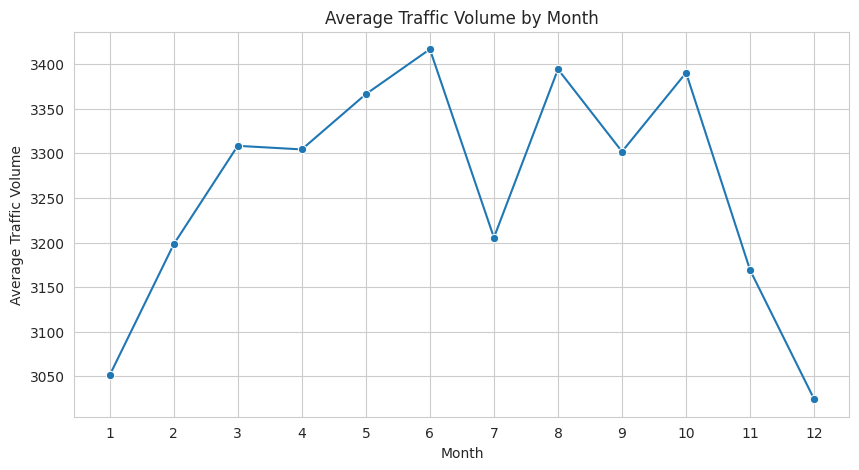

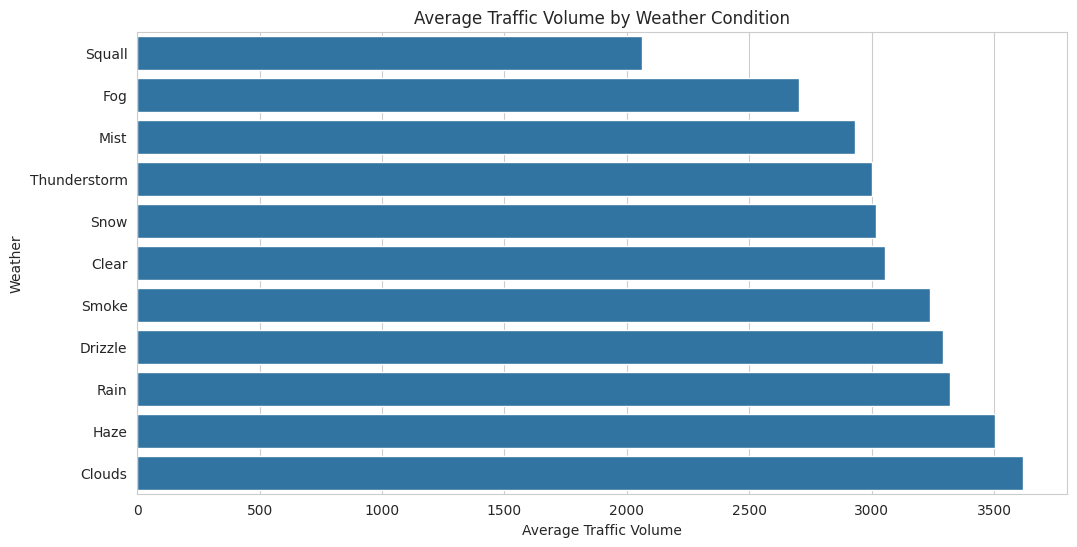

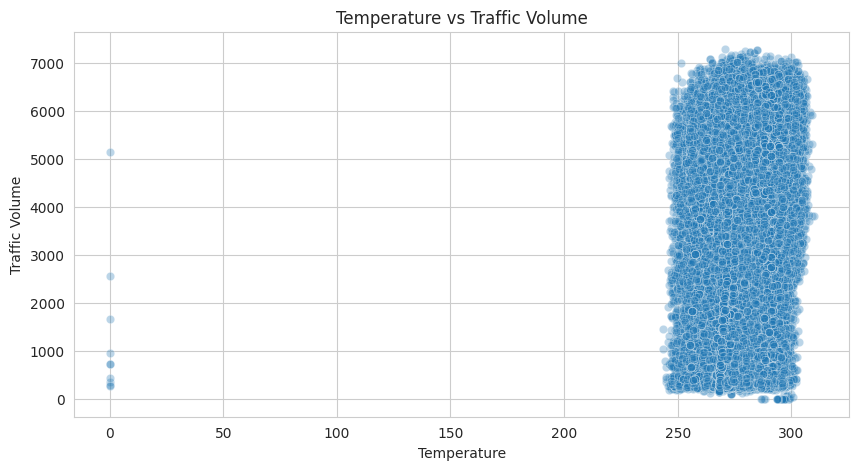

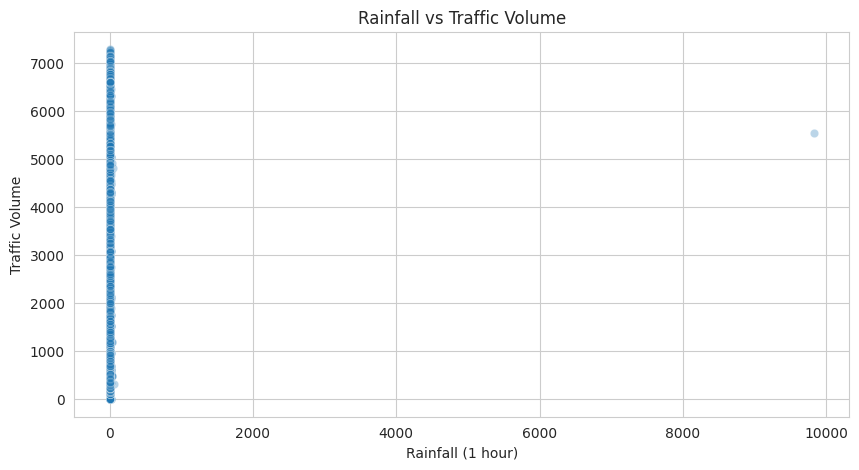

,date_time,hour,day_of_week,month,day,year,is_weekend,is_holiday
0,2012-10-02 09:00:00,9,1,10,2,2012,0,0
1,2012-10-02 10:00:00,10,1,10,2,2012,0,0
2,2012-10-02 11:00:00,11,1,10,2,2012,0,0
3,2012-10-02 12:00:00,12,1,10,2,2012,0,0
4,2012-10-02 13:00:00,13,1,10,2,2012,0,0



Training data shape: (38549, 15)
Testing data shape: (9638, 15)

Low Traffic Threshold: 2194.0
High Traffic Threshold: 4573.0

Training Traffic Distribution:
traffic_volume
Low       12851
Medium    12850
High      12848
Name: count, dtype: int64

Testing Traffic Distribution:
traffic_volume
Medium    3239
Low       3212
High      3187
Name: count, dtype: int64


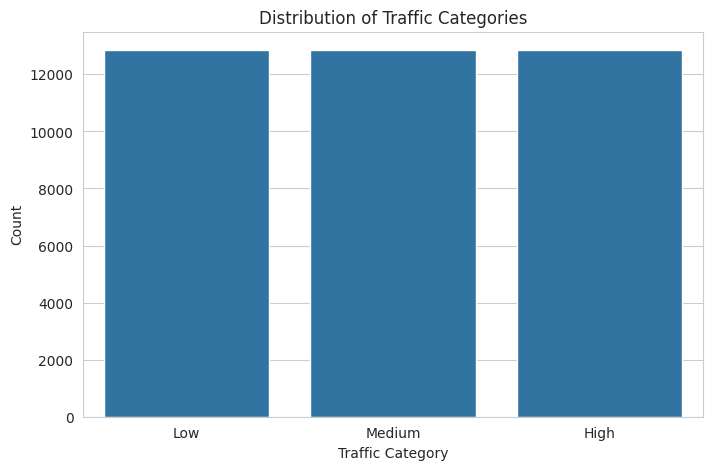


Training Logistic Regression...

Training Decision Tree...

Training Random Forest...

All models trained successfully!

Model Comparison Results


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.8761,0.8790,0.8761,0.8766
1,Decision Tree,0.8586,0.8595,0.8586,0.8586
2,Logistic Regression,0.6612,0.6605,0.6612,0.6601


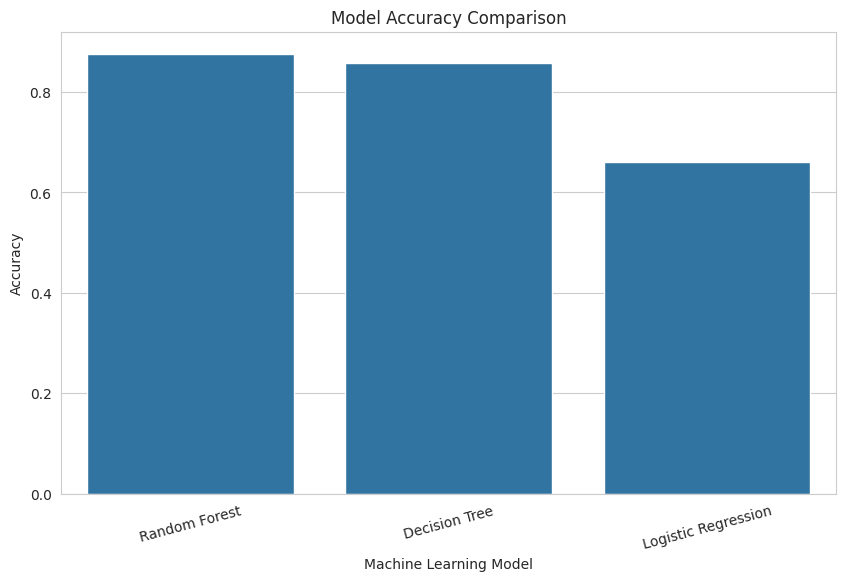


Best Model: Random Forest
Best Accuracy: 0.8761

Classification Report
              precision    recall  f1-score   support

         Low       0.97      0.90      0.93      3212
      Medium       0.82      0.81      0.82      3239
        High       0.84      0.92      0.88      3187

    accuracy                           0.88      9638
   macro avg       0.88      0.88      0.88      9638
weighted avg       0.88      0.88      0.88      9638



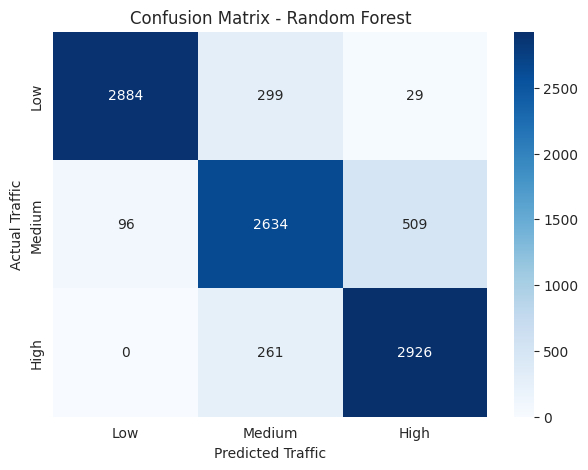

,Actual Traffic,Predicted Traffic
0,Medium,Medium
1,Medium,Medium
2,Medium,Medium
3,Medium,Medium
4,Medium,Medium
5,Low,Medium
6,Low,Medium
7,Low,Low
8,Low,Low
9,Low,Low


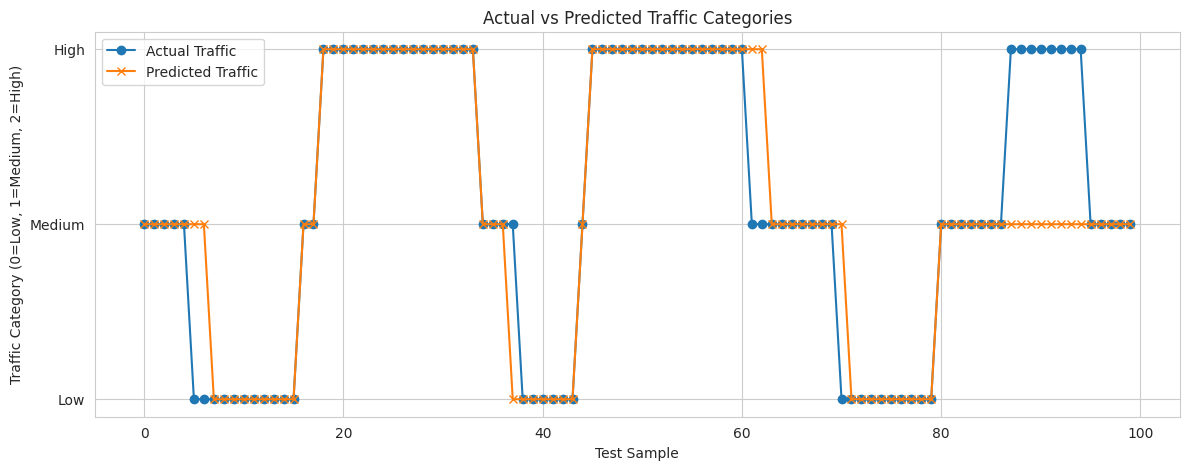

,Feature,Importance
0,num__hour,0.607543
1,num__temp,0.120097
2,num__day_of_week,0.061636
3,num__day,0.058835
4,num__month,0.037749
5,num__is_weekend,0.032354
6,num__clouds_all,0.028296
7,num__year,0.025070
8,num__rain_1h,0.008804
9,cat__weather_main_Clouds,0.004062


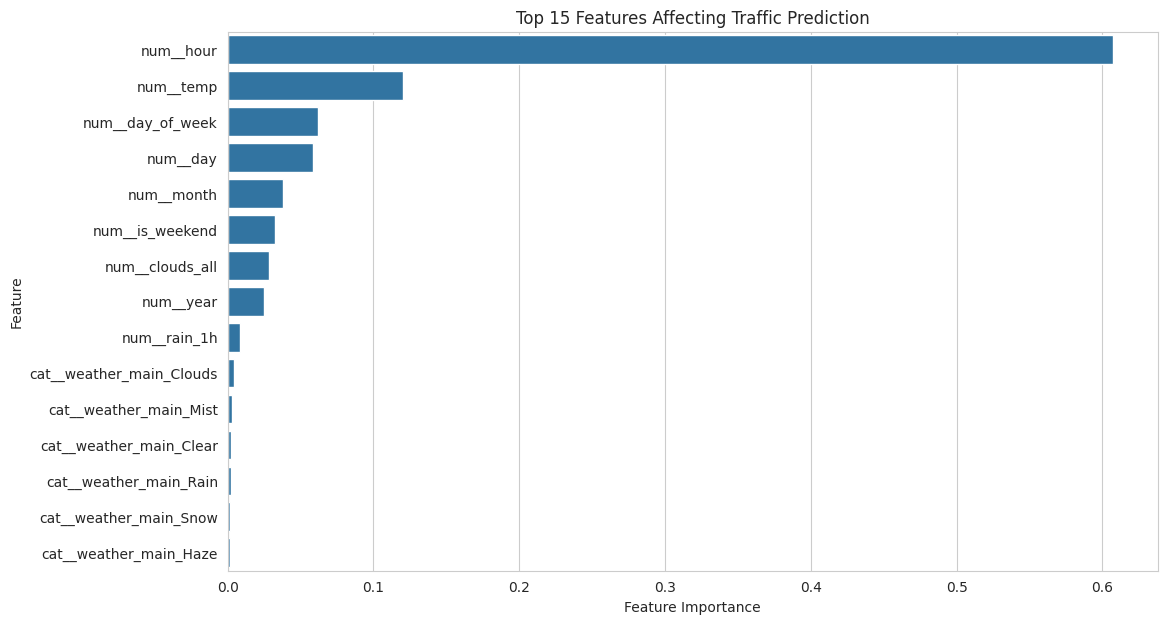


Sample Prediction
Predicted Traffic Category: Medium


,temp,rain_1h,snow_1h,clouds_all,hour,day_of_week,month,day,year,is_weekend,is_holiday,weather_main,holiday
38549,274.75,0.0,0.0,90,20,2,11,1,2017,0,0,Mist,NaN



All result files saved successfully!

Result files created:
1. model_comparison_results.csv
2. actual_vs_predicted_traffic.csv
3. feature_importance.csv
4. cleaned_traffic_dataset.csv
5. traffic_prediction_model.pkl


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib

warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

sns.set_style("whitegrid")

df = pd.read_csv('/content/Metro_Interstate_Traffic_Volume.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

df.info()

print("\nStatistical Summary")
display(df.describe())

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Records")
print("Number of duplicates:", df.duplicated().sum())

print("\nDataset Columns")
print(df.columns.tolist())

df = df.drop_duplicates()

df['date_time'] = pd.to_datetime(df['date_time'])

df = df.sort_values('date_time').reset_index(drop=True)

print("\nDataset shape after cleaning:", df.shape)

plt.figure(figsize=(10, 5))
sns.histplot(df['traffic_volume'], bins=50, kde=True)
plt.title('Distribution of Traffic Volume')
plt.xlabel('Traffic Volume')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(15, 5))
plt.plot(df['date_time'], df['traffic_volume'], linewidth=0.5)
plt.title('Traffic Volume Over Time')
plt.xlabel('Date')
plt.ylabel('Traffic Volume')
plt.show()

df['hour'] = df['date_time'].dt.hour

hourly_traffic = df.groupby('hour')['traffic_volume'].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=hourly_traffic.index, y=hourly_traffic.values, marker='o')
plt.title('Average Traffic Volume by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Traffic Volume')
plt.xticks(range(24))
plt.show()

df['day_of_week'] = df['date_time'].dt.dayofweek

daily_traffic = df.groupby('day_of_week')['traffic_volume'].mean()

plt.figure(figsize=(10, 5))
sns.barplot(x=daily_traffic.index, y=daily_traffic.values)
plt.title('Average Traffic Volume by Day of the Week')
plt.xlabel('Day of Week (0 = Monday, 6 = Sunday)')
plt.ylabel('Average Traffic Volume')
plt.show()

df['month'] = df['date_time'].dt.month

monthly_traffic = df.groupby('month')['traffic_volume'].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_traffic.index, y=monthly_traffic.values, marker='o')
plt.title('Average Traffic Volume by Month')
plt.xlabel('Month')
plt.ylabel('Average Traffic Volume')
plt.xticks(range(1, 13))
plt.show()

weather_traffic = df.groupby('weather_main')['traffic_volume'].mean().sort_values()

plt.figure(figsize=(12, 6))
sns.barplot(x=weather_traffic.values, y=weather_traffic.index)
plt.title('Average Traffic Volume by Weather Condition')
plt.xlabel('Average Traffic Volume')
plt.ylabel('Weather')
plt.show()

plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='temp', y='traffic_volume', alpha=0.3)
plt.title('Temperature vs Traffic Volume')
plt.xlabel('Temperature')
plt.ylabel('Traffic Volume')
plt.show()

plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='rain_1h', y='traffic_volume', alpha=0.3)
plt.title('Rainfall vs Traffic Volume')
plt.xlabel('Rainfall (1 hour)')
plt.ylabel('Traffic Volume')
plt.show()

df['day'] = df['date_time'].dt.day
df['year'] = df['date_time'].dt.year

df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)

df['is_holiday'] = (
    df['holiday'].notna() &
    (df['holiday'] != 'None')
).astype(int)

display(df[['date_time', 'hour', 'day_of_week', 'month',
             'day', 'year', 'is_weekend', 'is_holiday']].head())

X = df.drop(columns=['traffic_volume'])
y = df['traffic_volume']

split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train_volume = y.iloc[:split_index].copy()
y_test_volume = y.iloc[split_index:].copy()

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

low_threshold = y_train_volume.quantile(1/3)
high_threshold = y_train_volume.quantile(2/3)

print("\nLow Traffic Threshold:", low_threshold)
print("High Traffic Threshold:", high_threshold)

def categorize_traffic(volume):
    if volume <= low_threshold:
        return 'Low'
    elif volume <= high_threshold:
        return 'Medium'
    else:
        return 'High'

y_train = y_train_volume.apply(categorize_traffic)
y_test = y_test_volume.apply(categorize_traffic)

print("\nTraining Traffic Distribution:")
print(y_train.value_counts())

print("\nTesting Traffic Distribution:")
print(y_test.value_counts())

plt.figure(figsize=(8, 5))
sns.countplot(x=y_train, order=['Low', 'Medium', 'High'])
plt.title('Distribution of Traffic Categories')
plt.xlabel('Traffic Category')
plt.ylabel('Count')
plt.show()

numeric_features = [
    'temp',
    'rain_1h',
    'snow_1h',
    'clouds_all',
    'hour',
    'day_of_week',
    'month',
    'day',
    'year',
    'is_weekend',
    'is_holiday'
]

categorical_features = [
    'weather_main',
    'holiday'
]

X_train_model = X_train[numeric_features + categorical_features].copy()
X_test_model = X_test[numeric_features + categorical_features].copy()

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

decision_tree_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ))
])

random_forest_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])

models = {
    'Logistic Regression': logistic_model,
    'Decision Tree': decision_tree_model,
    'Random Forest': random_forest_model
}

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train_model, y_train)

print("\nAll models trained successfully!")

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_model)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred, average='weighted', zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, average='weighted', zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, y_pred, average='weighted', zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

print("\nModel Comparison Results")
display(results_df.round(4))

plt.figure(figsize=(10, 6))
sns.barplot(data=results_df, x='Model', y='Accuracy')
plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Model')
plt.ylabel('Accuracy')
plt.xticks(rotation=15)
plt.show()

best_model_name = results_df.loc[0, 'Model']
best_model = models[best_model_name]

print("\nBest Model:", best_model_name)
print("Best Accuracy:", round(results_df.loc[0, 'Accuracy'], 4))

y_pred_best = best_model.predict(X_test_model)

print("\nClassification Report")

print(classification_report(
    y_test,
    y_pred_best,
    labels=['Low', 'Medium', 'High'],
    zero_division=0
))

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=['Low', 'Medium', 'High']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted Traffic')
plt.ylabel('Actual Traffic')
plt.show()

comparison_df = pd.DataFrame({
    'Actual Traffic': y_test.values,
    'Predicted Traffic': y_pred_best
})

display(comparison_df.head(20))

traffic_mapping = {
    'Low': 0,
    'Medium': 1,
    'High': 2
}

actual_numeric = y_test.iloc[:100].map(traffic_mapping)
predicted_numeric = pd.Series(y_pred_best[:100]).map(traffic_mapping)

plt.figure(figsize=(14, 5))

plt.plot(
    range(len(actual_numeric)),
    actual_numeric,
    marker='o',
    label='Actual Traffic'
)

plt.plot(
    range(len(predicted_numeric)),
    predicted_numeric,
    marker='x',
    label='Predicted Traffic'
)

plt.title('Actual vs Predicted Traffic Categories')
plt.xlabel('Test Sample')
plt.ylabel('Traffic Category (0=Low, 1=Medium, 2=High)')
plt.yticks([0, 1, 2], ['Low', 'Medium', 'High'])
plt.legend()
plt.grid(True)
plt.show()

rf_model = models['Random Forest']

rf_classifier = rf_model.named_steps['classifier']
rf_preprocessor = rf_model.named_steps['preprocessor']

feature_names = rf_preprocessor.get_feature_names_out()
importance_values = rf_classifier.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance_values
})

feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

display(feature_importance_df.head(15))

top_features = feature_importance_df.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Features Affecting Traffic Prediction')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.show()

sample = X_test_model.iloc[[0]]

prediction = best_model.predict(sample)

print("\nSample Prediction")
print("Predicted Traffic Category:", prediction[0])

display(sample)

results_df.to_csv('model_comparison_results.csv', index=False)

comparison_df.to_csv('actual_vs_predicted_traffic.csv', index=False)

feature_importance_df.to_csv('feature_importance.csv', index=False)

df.to_csv('cleaned_traffic_dataset.csv', index=False)

joblib.dump(best_model, 'traffic_prediction_model.pkl')

print("\nAll result files saved successfully!")

print("\nResult files created:")
print("1. model_comparison_results.csv")
print("2. actual_vs_predicted_traffic.csv")
print("3. feature_importance.csv")
print("4. cleaned_traffic_dataset.csv")
print("5. traffic_prediction_model.pkl")